In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
path = '/content/drive/MyDrive/glaucoma-mtl/metadata_final.csv'
print("metadata_final.csv exists:", os.path.exists(path))

import pandas as pd
if os.path.exists(path):
    df = pd.read_csv(path)
    print(f"Rows: {len(df)}")
    print(f"Columns: {list(df.columns)}")
    print(f"Label distribution:\n{df['label'].value_counts()}")

Mounted at /content/drive
metadata_final.csv exists: True
Rows: 3000
Columns: ['names', 'label', 'fundus_path', 'od_path', 'oc_path', 'vcdr_final', 'severity_stage', 'has_severity', 'types']
Label distribution:
label
0    1500
1    1500
Name: count, dtype: int64


In [ ]:
import os

# Check if checkpoints folder exists in Drive
drive_ckpt = '/content/drive/MyDrive/glaucoma-mtl/checkpoints'
print("Drive checkpoints folder exists:", os.path.exists(drive_ckpt))
if os.path.exists(drive_ckpt):
    print("Contents:", os.listdir(drive_ckpt))

# Check what CKPT_DIR was set to in your training script
# It might have been set to local /content/ path
local_ckpt = '/content/glaucoma-mtl/checkpoints'
print("\nLocal checkpoints folder exists:", os.path.exists(local_ckpt))
if os.path.exists(local_ckpt):
    print("Contents:", os.listdir(local_ckpt))

# Search everywhere
print("\nSearching for .pth files...")
for root, dirs, files in os.walk('/content'):
    for f in files:
        if f.endswith('.pth'):
            print(os.path.join(root, f))

Drive checkpoints folder exists: False

Local checkpoints folder exists: False

Searching for .pth files...


In [ ]:
import os, sys, random, warnings
warnings.filterwarnings('ignore')

os.system('pip install -q timm scikit-learn matplotlib seaborn')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as transforms
import torchvision.models as models
import timm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, roc_auc_score, f1_score,
    confusion_matrix, classification_report
)

PROJECT_DIR  = '/content/drive/MyDrive/glaucoma-mtl'
DATA_DIR     = f'{PROJECT_DIR}/data/smdg19'
RESULTS_DIR  = f'{PROJECT_DIR}/results/baseline_densenet121'
CKPT_DIR     = f'{PROJECT_DIR}/checkpoints'
CSV_PATH     = f'{DATA_DIR}/metadata - standardized.csv'
CLEAN_CSV    = f'{PROJECT_DIR}/metadata_clean.csv'
FINAL_CSV    = f'{PROJECT_DIR}/metadata_final.csv'

PROPOSED_RESULTS_DIR = f'{PROJECT_DIR}/results/proposed_maxvit'
PROPOSED_CKPT        = f'{CKPT_DIR}/proposed_maxvit_best.pth'
ABLATION_RESULTS_DIR = f'{PROJECT_DIR}/results/ablation_maxvit_cbam_only'
ABLATION_CKPT        = f'{CKPT_DIR}/ablation_maxvit_cbam_best.pth'

for d in [RESULTS_DIR, CKPT_DIR, PROPOSED_RESULTS_DIR, ABLATION_RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}")
print(f"GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'None'}")

# Confirm metadata_final.csv exists before proceeding
assert os.path.exists(FINAL_CSV), f"metadata_final.csv not found at {FINAL_CSV}"
print(f"metadata_final.csv found: {FINAL_CSV}")
print("Setup complete.")

Device: cuda
GPU: Tesla T4
metadata_final.csv found: /content/drive/MyDrive/glaucoma-mtl/metadata_final.csv
Setup complete.


## STEP 2: DATASET + DATALOADERS

## SPEED FIX: Copy data to local Colab disk

Run this **ONCE** before building DataLoaders. Colab local disk is ~10x faster than Drive for image reads.

In [ ]:
import shutil, os, pandas as pd
from tqdm import tqdm

DRIVE_DATA = '/content/drive/MyDrive/glaucoma-mtl/data/smdg19'
LOCAL_DATA = '/content/smdg19'
os.makedirs(f'{LOCAL_DATA}/full-fundus/full-fundus', exist_ok=True)

# Load only the 3000 images we actually need
df = pd.read_csv('/content/drive/MyDrive/glaucoma-mtl/metadata_final.csv')
print(f"Copying only {len(df)} images needed for training...")

copied, skipped = 0, 0
for path in tqdm(df['fundus_path'], desc="Copying"):
    # Convert Drive path to local path
    local_path = path.replace(
        '/content/drive/MyDrive/glaucoma-mtl/data/smdg19',
        LOCAL_DATA
    )
    if not os.path.exists(local_path):
        os.makedirs(os.path.dirname(local_path), exist_ok=True)
        try:
            shutil.copy2(path, local_path)
            copied += 1
        except:
            skipped += 1
    else:
        skipped += 1

print(f"Done. Copied: {copied} | Already existed: {skipped}")

# Update paths in CSV to local
df['fundus_path'] = df['fundus_path'].str.replace(
    '/content/drive/MyDrive/glaucoma-mtl/data/smdg19',
    LOCAL_DATA, regex=False
)
LOCAL_FINAL_CSV = '/content/metadata_final_local.csv'
df.to_csv(LOCAL_FINAL_CSV, index=False)

# Verify
sample = df['fundus_path'].iloc[0]
print(f"Sample path: {sample}")
print(f"File exists: {os.path.isfile(sample)}")

FINAL_CSV = LOCAL_FINAL_CSV
print(f"FINAL_CSV updated to: {FINAL_CSV}")

Copying only 3000 images needed for training...


Copying: 100%|██████████| 3000/3000 [20:33<00:00,  2.43it/s]

Done. Copied: 3000 | Already existed: 0
Sample path: /content/smdg19/full-fundus/full-fundus/G1020-538.png
File exists: True
FINAL_CSV updated to: /content/metadata_final_local.csv


In [ ]:
class GlaucomaDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        label = int(row['label'])
        try:
            img = Image.open(row['fundus_path']).convert('RGB')
        except:
            img = Image.new('RGB', (224, 224), color=(0, 0, 0))
        if self.transform:
            img = self.transform(img)
        return img, label


class GlaucomaMultiTaskDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        label = int(row['label'])
        has_cdr = float(row['has_severity']) if 'has_severity' in row else 0.0
        cdr_val = float(row['vcdr_final']) if (
            has_cdr and not pd.isna(row.get('vcdr_final', float('nan')))
        ) else 0.0
        try:
            img = Image.open(row['fundus_path']).convert('RGB')
        except:
            img = Image.new('RGB', (224, 224), color=(0, 0, 0))
        if self.transform:
            img = self.transform(img)
        return img, label, torch.tensor(cdr_val, dtype=torch.float32), torch.tensor(has_cdr, dtype=torch.float32)


def get_transforms():
    mean = [0.485, 0.456, 0.406]
    std  = [0.229, 0.224, 0.225]
    train_t = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.RandomCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])
    val_t = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])
    return train_t, val_t


def get_dataloaders(csv_path, batch_size=32, seed=42):
    df = pd.read_csv(csv_path)
    train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df['label'], random_state=seed)
    val_df,  test_df  = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=seed)
    print(f"Split — Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
    train_t, val_t = get_transforms()
    train_ds = GlaucomaDataset(train_df, transform=train_t)
    val_ds   = GlaucomaDataset(val_df,   transform=val_t)
    test_ds  = GlaucomaDataset(test_df,  transform=val_t)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,  num_workers=2, pin_memory=True)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
    return train_loader, val_loader, test_loader, test_df


def get_multitask_dataloaders(csv_path, batch_size=16, seed=42):
    df = pd.read_csv(csv_path)
    train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df['label'], random_state=seed)
    val_df,  test_df  = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=seed)
    print(f"Split — Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
    print(f"CDR — Train: {train_df['has_severity'].sum():.0f} | Val: {val_df['has_severity'].sum():.0f} | Test: {test_df['has_severity'].sum():.0f}")
    train_t, val_t = get_transforms()
    train_ds = GlaucomaMultiTaskDataset(train_df, transform=train_t)
    val_ds   = GlaucomaMultiTaskDataset(val_df,   transform=val_t)
    test_ds  = GlaucomaMultiTaskDataset(test_df,  transform=val_t)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,  num_workers=2, pin_memory=True)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
    return train_loader, val_loader, test_loader, test_df


# Build both sets of loaders
print("Building single-task DataLoaders (for DenseNet baseline)...")
train_loader, val_loader, test_loader, test_df = get_dataloaders(FINAL_CSV)

print("\nBuilding multi-task DataLoaders (for proposed + ablation)...")
train_loader_mt, val_loader_mt, test_loader_mt, test_df_mt = get_multitask_dataloaders(FINAL_CSV)

print("\nDataLoaders ready.")

Building single-task DataLoaders (for DenseNet baseline)...
Split — Train: 2100 | Val: 450 | Test: 450

Building multi-task DataLoaders (for proposed + ablation)...
Split — Train: 2100 | Val: 450 | Test: 450
CDR — Train: 437 | Val: 90 | Test: 104

DataLoaders ready.


## STEP 3: ALL MODEL DEFINITIONS

In [ ]:
# ── DenseNet121 Baseline ──────────────────────────────────
class BaselineDenseNet121(nn.Module):
    def __init__(self, num_classes=2, dropout=0.4):
        super().__init__()
        base = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
        self.features   = base.features
        self.relu        = nn.ReLU(inplace=True)
        self.pool        = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier  = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(1024, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout - 0.1),
            nn.Linear(512, num_classes)
        )
    def forward(self, x):
        f = self.relu(self.features(x))
        f = torch.flatten(self.pool(f), 1)
        return self.classifier(f)


# ── Attention Modules ─────────────────────────────────────
class CBAM1D(nn.Module):
    """1D CBAM applied on flat feature vector from MaxViT global pool output."""
    def __init__(self, dim, reduction=16):
        super().__init__()
        self.channel_mlp = nn.Sequential(
            nn.Linear(dim, dim // reduction),
            nn.ReLU(),
            nn.Linear(dim // reduction, dim),
            nn.Sigmoid()
        )
    def forward(self, x):
        return x * self.channel_mlp(x)


class GCBlock1D(nn.Module):
    """1D Global Context Block — additive fusion, no channel collapse."""
    def __init__(self, dim, ratio=4):
        super().__init__()
        inner = max(dim // ratio, 1)
        self.context    = nn.Linear(dim, 1)
        self.transform  = nn.Sequential(
            nn.Linear(dim, inner),
            nn.LayerNorm(inner),
            nn.ReLU(),
            nn.Linear(inner, dim)
        )
    def forward(self, x):
        attn = torch.softmax(self.context(x), dim=1)
        ctx  = self.transform(x * attn)
        return x + ctx  # additive — key difference from SE/CBAM


# ── Proposed Model: MaxViT-Tiny + CBAM + GC Block ────────
class ProposedModel(nn.Module):
    def __init__(self, num_cls=2, dropout=0.4):
        super().__init__()
        self.backbone = timm.create_model(
            'maxvit_tiny_tf_224.in1k', pretrained=True,
            num_classes=0, global_pool='avg'
        )
        with torch.no_grad():
            dim = self.backbone(torch.zeros(1, 3, 224, 224)).shape[1]
        print(f"  MaxViT-Tiny output dim: {dim}")
        self.cbam    = CBAM1D(dim)
        self.gc      = GCBlock1D(dim)
        self.shared  = nn.Sequential(nn.Linear(dim, 512), nn.ReLU(), nn.Dropout(dropout))
        self.cls_head = nn.Sequential(nn.Linear(512,128), nn.ReLU(), nn.Dropout(dropout-0.1), nn.Linear(128, num_cls))
        self.reg_head = nn.Sequential(nn.Linear(512, 64),  nn.ReLU(), nn.Dropout(dropout-0.1), nn.Linear(64, 1), nn.Sigmoid())

    def forward(self, x):
        f = self.backbone(x)
        f = self.cbam(f)
        f = self.gc(f)
        s = self.shared(f)
        return self.cls_head(s), self.reg_head(s)


# ── Ablation Model: MaxViT-Tiny + CBAM only (no GC Block) ─
class AblationModelCBAMOnly(nn.Module):
    def __init__(self, num_cls=2, dropout=0.4):
        super().__init__()
        self.backbone = timm.create_model(
            'maxvit_tiny_tf_224.in1k', pretrained=True,
            num_classes=0, global_pool='avg'
        )
        with torch.no_grad():
            dim = self.backbone(torch.zeros(1, 3, 224, 224)).shape[1]
        print(f"  MaxViT-Tiny output dim: {dim}")
        self.cbam     = CBAM1D(dim)
        # NO GC Block
        self.shared   = nn.Sequential(nn.Linear(dim, 512), nn.ReLU(), nn.Dropout(dropout))
        self.cls_head = nn.Sequential(nn.Linear(512,128), nn.ReLU(), nn.Dropout(dropout-0.1), nn.Linear(128, num_cls))
        self.reg_head = nn.Sequential(nn.Linear(512, 64),  nn.ReLU(), nn.Dropout(dropout-0.1), nn.Linear(64, 1), nn.Sigmoid())

    def forward(self, x):
        f = self.backbone(x)
        f = self.cbam(f)   # CBAM only — no GC
        s = self.shared(f)
        return self.cls_head(s), self.reg_head(s)


print("All model classes defined.")

All model classes defined.


## STEP 4: TRAINING FUNCTIONS — NO EARLY STOPPING

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, labels in tqdm(loader, desc="  Train", leave=False):
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total   += imgs.size(0)
    return total_loss / total, correct / total


def validate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_probs, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in tqdm(loader, desc="  Val", leave=False):
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * imgs.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total   += imgs.size(0)
            probs = torch.softmax(outputs, 1)[:, 1]
            all_probs.extend(probs.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    return total_loss/total, correct/total, roc_auc_score(all_labels, all_probs)


def multitask_loss(cls_out, cls_labels, reg_out, cdr_vals, cdr_masks,
                   cls_weight=1.0, reg_weight=0.5):
    cls_loss = nn.CrossEntropyLoss()(cls_out, cls_labels)
    reg_sq   = reg_out.squeeze(1)
    mse      = (reg_sq - cdr_vals) ** 2
    n_cdr    = cdr_masks.sum().clamp(min=1)
    reg_loss = (mse * cdr_masks).sum() / n_cdr
    return cls_weight * cls_loss + reg_weight * reg_loss, cls_loss, reg_loss


def train_one_epoch_mt(model, loader, optimizer):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, cls_labels, cdr_vals, cdr_masks in tqdm(loader, desc="  Train", leave=False):
        imgs, cls_labels = imgs.to(DEVICE), cls_labels.to(DEVICE)
        cdr_vals, cdr_masks = cdr_vals.to(DEVICE), cdr_masks.to(DEVICE)
        optimizer.zero_grad()
        cls_out, reg_out = model(imgs)
        loss, _, _ = multitask_loss(cls_out, cls_labels, reg_out, cdr_vals, cdr_masks)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct += (cls_out.argmax(1) == cls_labels).sum().item()
        total   += imgs.size(0)
    return total_loss/total, correct/total


def validate_mt(model, loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_probs, all_labels = [], []
    cdr_preds, cdr_true = [], []
    with torch.no_grad():
        for imgs, cls_labels, cdr_vals, cdr_masks in tqdm(loader, desc="  Val", leave=False):
            imgs, cls_labels = imgs.to(DEVICE), cls_labels.to(DEVICE)
            cdr_vals, cdr_masks = cdr_vals.to(DEVICE), cdr_masks.to(DEVICE)
            cls_out, reg_out = model(imgs)
            loss, _, _ = multitask_loss(cls_out, cls_labels, reg_out, cdr_vals, cdr_masks)
            total_loss += loss.item() * imgs.size(0)
            correct += (cls_out.argmax(1) == cls_labels).sum().item()
            total   += imgs.size(0)
            probs = torch.softmax(cls_out, 1)[:, 1]
            all_probs.extend(probs.cpu().numpy())
            all_labels.extend(cls_labels.cpu().numpy())
            mask_bool = cdr_masks.bool()
            if mask_bool.any():
                cdr_preds.extend(reg_out.squeeze(1)[mask_bool].cpu().numpy())
                cdr_true.extend(cdr_vals[mask_bool].cpu().numpy())
    auc = roc_auc_score(all_labels, all_probs)
    mae = float(np.mean(np.abs(np.array(cdr_preds) - np.array(cdr_true)))) if cdr_preds else 0.0
    return total_loss/total, correct/total, auc, mae


# ── Baseline training (no early stopping) ────────────────
def train_baseline(model, train_loader, val_loader,
                   ckpt_path, num_epochs=50, lr=1e-4,
                   weight_decay=1e-4, unfreeze_epoch=6):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, weight_decay=weight_decay
    )
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=4)
    best_auc  = 0.0
    history   = {'train_loss':[], 'val_loss':[], 'train_acc':[], 'val_acc':[], 'val_auc':[]}

    for epoch in range(1, num_epochs + 1):
        if epoch == unfreeze_epoch:
            print(f"\nEpoch {epoch}: Unfreezing backbone...")
            for p in model.features.parameters():
                p.requires_grad = True
            optimizer = optim.Adam(model.parameters(), lr=lr*0.1, weight_decay=weight_decay)
            scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=4)

        tl, ta = train_one_epoch(model, train_loader, criterion, optimizer)
        vl, va, vauc = validate(model, val_loader, criterion)
        scheduler.step(vauc)

        history['train_loss'].append(tl)
        history['val_loss'].append(vl)
        history['train_acc'].append(ta)
        history['val_acc'].append(va)
        history['val_auc'].append(vauc)

        print(f"Epoch [{epoch:02d}/{num_epochs}] TrLoss:{tl:.4f} TrAcc:{ta:.4f} VlLoss:{vl:.4f} VlAcc:{va:.4f} VlAUC:{vauc:.4f}")

        if vauc > best_auc:
            best_auc = vauc
            torch.save({'epoch':epoch, 'model_state_dict':model.state_dict(),
                        'optimizer_state_dict':optimizer.state_dict(),
                        'val_auc':vauc, 'val_acc':va}, ckpt_path)
            print(f"  ✓ Saved (AUC:{best_auc:.4f})")

    print(f"\nDone. Best Val AUC: {best_auc:.4f} | Checkpoint: {ckpt_path}")
    return history, ckpt_path


# ── Proposed / Ablation training (no early stopping) ─────
def train_proposed(model, train_loader, val_loader,
                   ckpt_path, num_epochs=50, lr=1e-4,
                   weight_decay=1e-4, unfreeze_epoch=6):
    optimizer = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, weight_decay=weight_decay
    )
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=4)
    best_auc  = 0.0
    history   = {'train_loss':[], 'val_loss':[], 'train_acc':[], 'val_acc':[], 'val_auc':[], 'val_cdr_mae':[]}

    for epoch in range(1, num_epochs + 1):
        if epoch == unfreeze_epoch:
            print(f"\nEpoch {epoch}: Unfreezing backbone...")
            for p in model.backbone.parameters():
                p.requires_grad = True
            optimizer = optim.Adam(model.parameters(), lr=lr*0.1, weight_decay=weight_decay)
            scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=4)

        tl, ta = train_one_epoch_mt(model, train_loader, optimizer)
        vl, va, vauc, vmae = validate_mt(model, val_loader)
        scheduler.step(vauc)

        history['train_loss'].append(tl)
        history['val_loss'].append(vl)
        history['train_acc'].append(ta)
        history['val_acc'].append(va)
        history['val_auc'].append(vauc)
        history['val_cdr_mae'].append(vmae)

        print(f"Epoch [{epoch:02d}/{num_epochs}] TrLoss:{tl:.4f} TrAcc:{ta:.4f} VlLoss:{vl:.4f} VlAcc:{va:.4f} VlAUC:{vauc:.4f} CDR_MAE:{vmae:.4f}")

        if vauc > best_auc:
            best_auc = vauc
            torch.save({'epoch':epoch, 'model_state_dict':model.state_dict(),
                        'optimizer_state_dict':optimizer.state_dict(),
                        'val_auc':vauc, 'val_acc':va, 'val_cdr_mae':vmae}, ckpt_path)
            print(f"  ✓ Saved (AUC:{best_auc:.4f})")

    print(f"\nDone. Best Val AUC: {best_auc:.4f} | Checkpoint: {ckpt_path}")
    return history, ckpt_path


print("All training functions defined.")

All training functions defined.


## STEP 5A: TRAIN DENSENET121 BASELINE

In [ ]:
print("Building DenseNet121 baseline...")
baseline_model = BaselineDenseNet121(num_classes=2).to(DEVICE)
for p in baseline_model.features.parameters():
    p.requires_grad = False  # freeze backbone Phase 1
print(f"Trainable params: {sum(p.numel() for p in baseline_model.parameters() if p.requires_grad):,}")

BASELINE_CKPT = f'{CKPT_DIR}/baseline_densenet121_best.pth'
print("Starting DenseNet121 training (50 epochs, no early stopping)...")
history_baseline, best_ckpt_baseline = train_baseline(
    baseline_model, train_loader, val_loader,
    ckpt_path=BASELINE_CKPT,
    num_epochs=50, lr=1e-4, weight_decay=1e-4, unfreeze_epoch=6
)

Building DenseNet121 baseline...
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 114MB/s]


Trainable params: 525,826
Starting DenseNet121 training (50 epochs, no early stopping)...


Epoch [01/50] TrLoss:0.6693 TrAcc:0.5800 VlLoss:0.6345 VlAcc:0.6178 VlAUC:0.7735
  ✓ Saved (AUC:0.7735)


Epoch [02/50] TrLoss:0.6239 TrAcc:0.6438 VlLoss:0.6224 VlAcc:0.6222 VlAUC:0.7912
  ✓ Saved (AUC:0.7912)


...

Epoch [46/50] TrLoss:0.1804 TrAcc:0.9248 VlLoss:0.4419 VlAcc:0.7978 VlAUC:0.9273


Epoch [47/50] TrLoss:0.1925 TrAcc:0.9171 VlLoss:0.4357 VlAcc:0.8044 VlAUC:0.9261


Epoch [48/50] TrLoss:0.1712 TrAcc:0.9305 VlLoss:0.4430 VlAcc:0.8000 VlAUC:0.9268


Epoch [49/50] TrLoss:0.1973 TrAcc:0.9129 VlLoss:0.4278 VlAcc:0.8000 VlAUC:0.9271


Epoch [50/50] TrLoss:0.1978 TrAcc:0.9181 VlLoss:0.4430 VlAcc:0.7956 VlAUC:0.9275

Done. Best Val AUC: 0.9297 | Checkpoint: /content/drive/MyDrive/glaucoma-mtl/checkpoints/baseline_densenet121_best.pth


## STEP 5B: EVALUATE DENSENET121

Evaluating: 100%|██████████| 15/15 [00:03<00:00,  3.85it/s]



DENSENET121 BASELINE — TEST RESULTS
  Train Acc (final epoch): 91.81%
  Val   Acc (final epoch): 79.56%
  Best  Val Accuracy:      83.33%
  Test  Accuracy:          81.11%
  Test  Loss:              0.4219
  AUC-ROC:                 0.9237
  Macro F1:                0.8092
  Weighted F1:             0.8092
  Sensitivity (Glaucoma):  91.11%
  Specificity (Normal):    71.11%
  Precision Non-Glaucoma:  88.89%
  Precision Glaucoma:      75.93%
  Recall Non-Glaucoma:     71.11%
  Recall Glaucoma:         91.11%
              precision    recall  f1-score   support

Non-Glaucoma       0.89      0.71      0.79       225
    Glaucoma       0.76      0.91      0.83       225

    accuracy                           0.81       450
   macro avg       0.82      0.81      0.81       450
weighted avg       0.82      0.81      0.81       450



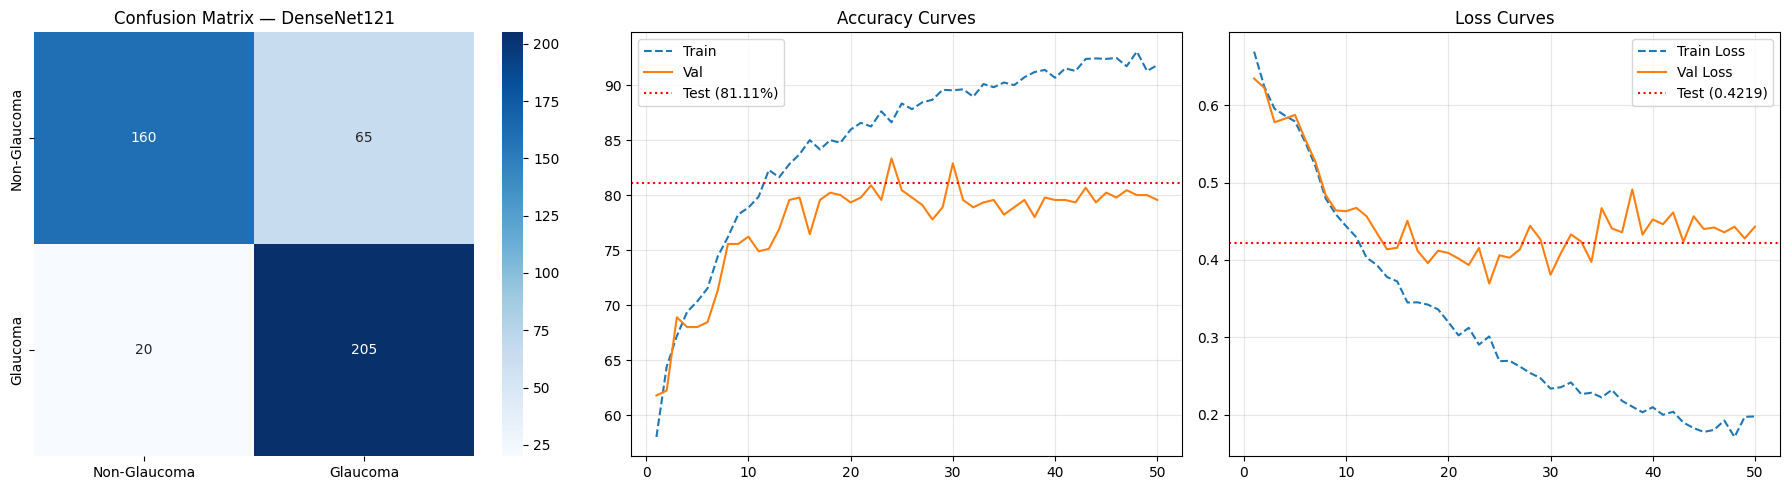

Results saved to: /content/drive/MyDrive/glaucoma-mtl/results/baseline_densenet121


In [ ]:
def evaluate_baseline(model, test_loader, best_ckpt, results_dir, history):
    from sklearn.metrics import precision_score, recall_score

    ckpt = torch.load(best_ckpt, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ckpt['model_state_dict'])
    model.eval()

    all_preds, all_probs, all_labels = [], [], []
    test_loss_total, test_total = 0.0, 0
    criterion = nn.CrossEntropyLoss()

    with torch.no_grad():
        for imgs, labels in tqdm(test_loader, desc="Evaluating"):
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            test_loss_total += loss.item() * imgs.size(0)
            test_total += imgs.size(0)
            probs = torch.softmax(outputs, 1)[:, 1]
            all_preds.extend(outputs.argmax(1).cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    all_preds  = np.array(all_preds)
    all_probs  = np.array(all_probs)
    all_labels = np.array(all_labels)

    test_loss = test_loss_total / test_total
    acc = accuracy_score(all_labels, all_preds)
    auc = roc_auc_score(all_labels, all_probs)
    f1w = f1_score(all_labels, all_preds, average='weighted')
    f1m = f1_score(all_labels, all_preds, average='macro')
    cm  = confusion_matrix(all_labels, all_preds)
    tn, fp, fn, tp = cm.ravel()
    sens = tp / (tp + fn)
    spec = tn / (tn + fp)
    prec = precision_score(all_labels, all_preds, average=None)
    rec  = recall_score(all_labels, all_preds, average=None)
    best_val_acc = max(history['val_acc']) * 100

    print("\n" + "="*65)
    print("DENSENET121 BASELINE — TEST RESULTS")
    print("="*65)
    print(f"  Train Acc (final epoch): {history['train_acc'][-1]*100:.2f}%")
    print(f"  Val   Acc (final epoch): {history['val_acc'][-1]*100:.2f}%")
    print(f"  Best  Val Accuracy:      {best_val_acc:.2f}%")
    print(f"  Test  Accuracy:          {acc*100:.2f}%")
    print(f"  Test  Loss:              {test_loss:.4f}")
    print(f"  AUC-ROC:                 {auc:.4f}")
    print(f"  Macro F1:                {f1m:.4f}")
    print(f"  Weighted F1:             {f1w:.4f}")
    print(f"  Sensitivity (Glaucoma):  {sens*100:.2f}%")
    print(f"  Specificity (Normal):    {spec*100:.2f}%")
    print(f"  Precision Non-Glaucoma:  {prec[0]*100:.2f}%")
    print(f"  Precision Glaucoma:      {prec[1]*100:.2f}%")
    print(f"  Recall Non-Glaucoma:     {rec[0]*100:.2f}%")
    print(f"  Recall Glaucoma:         {rec[1]*100:.2f}%")
    print(classification_report(all_labels, all_preds, target_names=['Non-Glaucoma','Glaucoma']))

    os.makedirs(results_dir, exist_ok=True)
    with open(f'{results_dir}/baseline_metrics.txt', 'w') as f:
        f.write(f"Test Accuracy: {acc*100:.2f}%\nAUC-ROC: {auc:.4f}\nMacro F1: {f1m:.4f}\n"
                f"Sensitivity: {sens*100:.2f}%\nSpecificity: {spec*100:.2f}%\n"
                f"Test Loss: {test_loss:.4f}\n")

    epochs_r = range(1, len(history['train_loss'])+1)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
                xticklabels=['Non-Glaucoma','Glaucoma'], yticklabels=['Non-Glaucoma','Glaucoma'])
    axes[0].set_title('Confusion Matrix — DenseNet121')
    axes[1].plot(epochs_r, [v*100 for v in history['train_acc']], '--', label='Train')
    axes[1].plot(epochs_r, [v*100 for v in history['val_acc']], label='Val')
    axes[1].axhline(y=acc*100, color='red', linestyle=':', label=f'Test ({acc*100:.2f}%)')
    axes[1].set_title('Accuracy Curves'); axes[1].legend(); axes[1].grid(alpha=0.3)
    axes[2].plot(epochs_r, history['train_loss'], '--', label='Train Loss')
    axes[2].plot(epochs_r, history['val_loss'], label='Val Loss')
    axes[2].axhline(y=test_loss, color='red', linestyle=':', label=f'Test ({test_loss:.4f})')
    axes[2].set_title('Loss Curves'); axes[2].legend(); axes[2].grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f'{results_dir}/baseline_results.png', dpi=150)
    plt.show()
    print(f"Results saved to: {results_dir}")
    return acc, auc, f1m, sens, spec

acc_d, auc_d, f1_d, sens_d, spec_d = evaluate_baseline(
    baseline_model, test_loader, BASELINE_CKPT, RESULTS_DIR, history_baseline
)

## STEP 6A: TRAIN PROPOSED MODEL (MaxViT-Tiny + CBAM + GC)

In [ ]:
print("Building Proposed Model (MaxViT-Tiny + CBAM + GC Block)...")
proposed_model = ProposedModel(num_cls=2, dropout=0.4).to(DEVICE)
for p in proposed_model.backbone.parameters():
    p.requires_grad = False  # freeze backbone Phase 1
total     = sum(p.numel() for p in proposed_model.parameters())
trainable = sum(p.numel() for p in proposed_model.parameters() if p.requires_grad)
print(f"Total params: {total:,} | Trainable (Phase 1): {trainable:,}")

print("Starting Proposed Model training (50 epochs, no early stopping)...")
history_proposed, best_ckpt_proposed = train_proposed(
    proposed_model, train_loader_mt, val_loader_mt,
    ckpt_path=PROPOSED_CKPT,
    num_epochs=50, lr=1e-4, weight_decay=1e-4, unfreeze_epoch=6
)

Building Proposed Model (MaxViT-Tiny + CBAM + GC Block)...


model.safetensors: reconstructing file:   0%|          |  0.00B /  124MB            

model.safetensors: downloading bytes:           |  0.00B            

  MaxViT-Tiny output dim: 512
Total params: 30,930,796 | Trainable (Phase 1): 527,268
Starting Proposed Model training (50 epochs, no early stopping)...


Epoch [01/50] TrLoss:0.6708 TrAcc:0.6019 VlLoss:0.5902 VlAcc:0.6956 VlAUC:0.8052 CDR_MAE:0.0996
  ✓ Saved (AUC:0.8052)


...

Epoch [46/50] TrLoss:0.0918 TrAcc:0.9695 VlLoss:0.4820 VlAcc:0.8444 VlAUC:0.9269 CDR_MAE:0.0662


Epoch [47/50] TrLoss:0.0828 TrAcc:0.9719 VlLoss:0.5039 VlAcc:0.8333 VlAUC:0.9283 CDR_MAE:0.0675


Epoch [48/50] TrLoss:0.0871 TrAcc:0.9676 VlLoss:0.4796 VlAcc:0.8467 VlAUC:0.9270 CDR_MAE:0.0654


Epoch [49/50] TrLoss:0.0894 TrAcc:0.9686 VlLoss:0.4797 VlAcc:0.8400 VlAUC:0.9291 CDR_MAE:0.0660


Epoch [50/50] TrLoss:0.0893 TrAcc:0.9695 VlLoss:0.5159 VlAcc:0.8311 VlAUC:0.9269 CDR_MAE:0.0672

Done. Best Val AUC: 0.9299 | Checkpoint: /content/drive/MyDrive/glaucoma-mtl/checkpoints/proposed_maxvit_best.pth


## STEP 6B: EVALUATE PROPOSED MODEL

Evaluating: 100%|██████████| 29/29 [00:06<00:00,  4.17it/s]



PROPOSED MODEL — TEST RESULTS
  Train Acc (final epoch): 96.95%
  Val   Acc (final epoch): 83.11%
  Best  Val Accuracy:      85.78%
  Test  Accuracy:          81.56%
  Test  Loss:              0.4075
  AUC-ROC:                 0.9185
  Macro F1:                0.8153
  Weighted F1:             0.8153
  Sensitivity (Glaucoma):  77.78%
  Specificity (Normal):    85.33%
  Precision Non-Glaucoma:  79.34%
  Precision Glaucoma:      84.13%
  CDR MAE:                 0.0760
  CDR RMSE:                0.0960
  CDR Test Samples:        104
              precision    recall  f1-score   support

Non-Glaucoma       0.79      0.85      0.82       225
    Glaucoma       0.84      0.78      0.81       225

    accuracy                           0.82       450
   macro avg       0.82      0.82      0.82       450
weighted avg       0.82      0.82      0.82       450



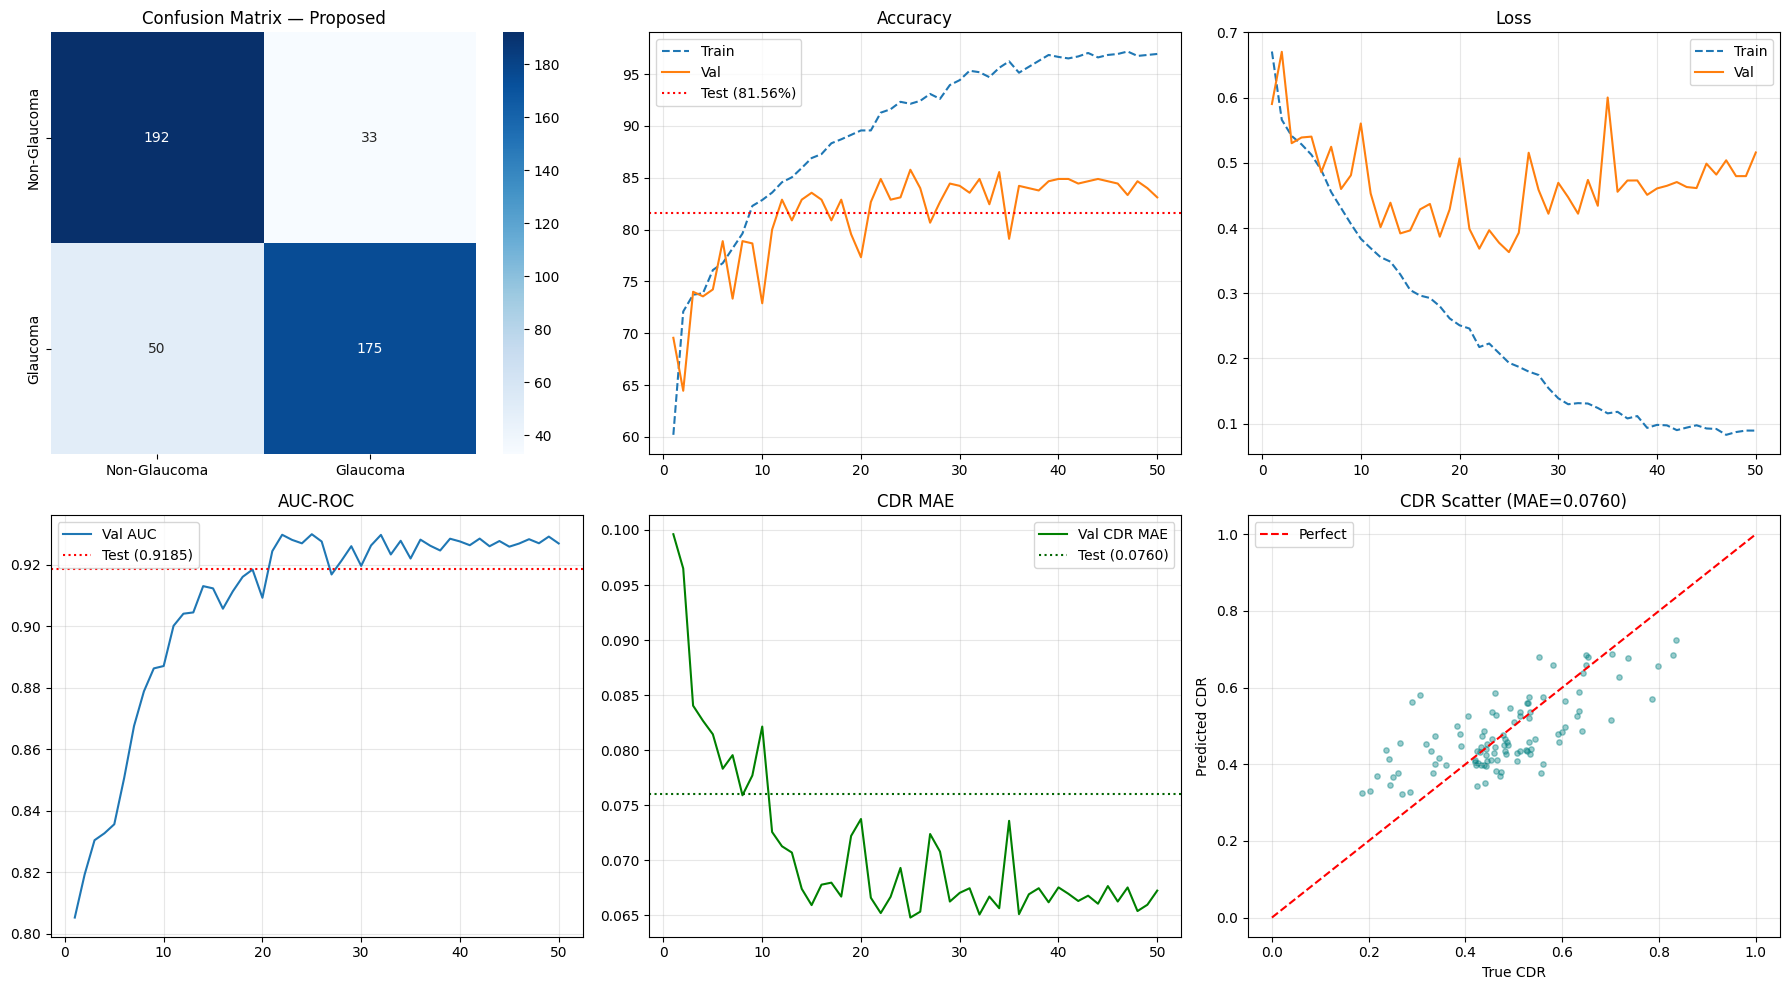

Results saved to: /content/drive/MyDrive/glaucoma-mtl/results/proposed_maxvit


In [ ]:
def evaluate_proposed(model, test_loader, best_ckpt, results_dir, history_mt):
    from sklearn.metrics import precision_score, recall_score

    ckpt = torch.load(best_ckpt, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ckpt['model_state_dict'])
    model.eval()

    all_preds, all_probs, all_labels = [], [], []
    cdr_preds_list, cdr_true_list = [], []
    test_loss_total, test_total = 0.0, 0

    with torch.no_grad():
        for imgs, cls_labels, cdr_vals, cdr_masks in tqdm(test_loader, desc="Evaluating"):
            imgs, cls_labels = imgs.to(DEVICE), cls_labels.to(DEVICE)
            cdr_vals, cdr_masks = cdr_vals.to(DEVICE), cdr_masks.to(DEVICE)
            cls_out, reg_out = model(imgs)
            loss, _, _ = multitask_loss(cls_out, cls_labels, reg_out, cdr_vals, cdr_masks)
            test_loss_total += loss.item() * imgs.size(0)
            test_total += imgs.size(0)
            probs = torch.softmax(cls_out, 1)[:, 1]
            all_preds.extend(cls_out.argmax(1).cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
            all_labels.extend(cls_labels.cpu().numpy())
            mask_bool = cdr_masks.bool()
            if mask_bool.any():
                cdr_preds_list.extend(reg_out.squeeze(1)[mask_bool].cpu().numpy())
                cdr_true_list.extend(cdr_vals[mask_bool].cpu().numpy())

    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)
    all_labels = np.array(all_labels)
    cdr_preds = np.array(cdr_preds_list)
    cdr_true  = np.array(cdr_true_list)

    test_loss = test_loss_total / test_total
    acc = accuracy_score(all_labels, all_preds)
    auc = roc_auc_score(all_labels, all_probs)
    f1m = f1_score(all_labels, all_preds, average='macro')
    f1w = f1_score(all_labels, all_preds, average='weighted')
    cm  = confusion_matrix(all_labels, all_preds)
    tn, fp, fn, tp = cm.ravel()
    sens = tp / (tp + fn)
    spec = tn / (tn + fp)
    prec = precision_score(all_labels, all_preds, average=None)
    rec  = recall_score(all_labels, all_preds, average=None)
    cdr_mae  = float(np.mean(np.abs(cdr_preds - cdr_true)))
    cdr_rmse = float(np.sqrt(np.mean((cdr_preds - cdr_true)**2)))
    best_val_acc = max(history_mt['val_acc']) * 100

    print("\n" + "="*65)
    print("PROPOSED MODEL — TEST RESULTS")
    print("="*65)
    print(f"  Train Acc (final epoch): {history_mt['train_acc'][-1]*100:.2f}%")
    print(f"  Val   Acc (final epoch): {history_mt['val_acc'][-1]*100:.2f}%")
    print(f"  Best  Val Accuracy:      {best_val_acc:.2f}%")
    print(f"  Test  Accuracy:          {acc*100:.2f}%")
    print(f"  Test  Loss:              {test_loss:.4f}")
    print(f"  AUC-ROC:                 {auc:.4f}")
    print(f"  Macro F1:                {f1m:.4f}")
    print(f"  Weighted F1:             {f1w:.4f}")
    print(f"  Sensitivity (Glaucoma):  {sens*100:.2f}%")
    print(f"  Specificity (Normal):    {spec*100:.2f}%")
    print(f"  Precision Non-Glaucoma:  {prec[0]*100:.2f}%")
    print(f"  Precision Glaucoma:      {prec[1]*100:.2f}%")
    print(f"  CDR MAE:                 {cdr_mae:.4f}")
    print(f"  CDR RMSE:                {cdr_rmse:.4f}")
    print(f"  CDR Test Samples:        {len(cdr_preds)}")
    print(classification_report(all_labels, all_preds, target_names=['Non-Glaucoma','Glaucoma']))

    os.makedirs(results_dir, exist_ok=True)
    with open(f'{results_dir}/proposed_metrics.txt', 'w') as f:
        f.write(f"Test Accuracy: {acc*100:.2f}%\nAUC-ROC: {auc:.4f}\nMacro F1: {f1m:.4f}\n"
                f"Sensitivity: {sens*100:.2f}%\nSpecificity: {spec*100:.2f}%\n"
                f"Test Loss: {test_loss:.4f}\nCDR MAE: {cdr_mae:.4f}\nCDR RMSE: {cdr_rmse:.4f}\n")

    epochs_r = range(1, len(history_mt['train_loss'])+1)
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0,0],
                xticklabels=['Non-Glaucoma','Glaucoma'], yticklabels=['Non-Glaucoma','Glaucoma'])
    axes[0,0].set_title('Confusion Matrix — Proposed')
    axes[0,1].plot(epochs_r, [v*100 for v in history_mt['train_acc']], '--', label='Train')
    axes[0,1].plot(epochs_r, [v*100 for v in history_mt['val_acc']], label='Val')
    axes[0,1].axhline(y=acc*100, color='red', linestyle=':', label=f'Test ({acc*100:.2f}%)')
    axes[0,1].set_title('Accuracy'); axes[0,1].legend(); axes[0,1].grid(alpha=0.3)
    axes[0,2].plot(epochs_r, history_mt['train_loss'], '--', label='Train')
    axes[0,2].plot(epochs_r, history_mt['val_loss'], label='Val')
    axes[0,2].set_title('Loss'); axes[0,2].legend(); axes[0,2].grid(alpha=0.3)
    axes[1,0].plot(epochs_r, history_mt['val_auc'], label='Val AUC')
    axes[1,0].axhline(y=auc, color='red', linestyle=':', label=f'Test ({auc:.4f})')
    axes[1,0].set_title('AUC-ROC'); axes[1,0].legend(); axes[1,0].grid(alpha=0.3)
    axes[1,1].plot(epochs_r, history_mt['val_cdr_mae'], color='green', label='Val CDR MAE')
    axes[1,1].axhline(y=cdr_mae, color='darkgreen', linestyle=':', label=f'Test ({cdr_mae:.4f})')
    axes[1,1].set_title('CDR MAE'); axes[1,1].legend(); axes[1,1].grid(alpha=0.3)
    axes[1,2].scatter(cdr_true, cdr_preds, alpha=0.4, color='teal', s=15)
    axes[1,2].plot([0,1],[0,1],'r--', label='Perfect')
    axes[1,2].set_title(f'CDR Scatter (MAE={cdr_mae:.4f})')
    axes[1,2].set_xlabel('True CDR'); axes[1,2].set_ylabel('Predicted CDR')
    axes[1,2].legend(); axes[1,2].grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f'{results_dir}/proposed_results.png', dpi=150)
    plt.show()
    print(f"Results saved to: {results_dir}")
    return acc, auc, f1m, sens, spec, cdr_mae, cdr_rmse

acc_p, auc_p, f1_p, sens_p, spec_p, mae_p, rmse_p = evaluate_proposed(
    proposed_model, test_loader_mt, PROPOSED_CKPT, PROPOSED_RESULTS_DIR, history_proposed
)

## STEP 7A: TRAIN ABLATION MODEL (MaxViT-Tiny + CBAM only)

In [ ]:
print("Building Ablation Model (MaxViT-Tiny + CBAM, no GC Block)...")
ablation_model = AblationModelCBAMOnly(num_cls=2, dropout=0.4).to(DEVICE)
for p in ablation_model.backbone.parameters():
    p.requires_grad = False
print(f"Trainable (Phase 1): {sum(p.numel() for p in ablation_model.parameters() if p.requires_grad):,}")

print("Starting Ablation training (50 epochs, no early stopping)...")
history_ablation, _ = train_proposed(
    ablation_model, train_loader_mt, val_loader_mt,
    ckpt_path=ABLATION_CKPT,
    num_epochs=50, lr=1e-4, weight_decay=1e-4, unfreeze_epoch=6
)

Building Ablation Model (MaxViT-Tiny + CBAM, no GC Block)...


  MaxViT-Tiny output dim: 512
Trainable (Phase 1): 394,787
Starting Ablation training (50 epochs, no early stopping)...


Epoch [01/50] TrLoss:0.6897 TrAcc:0.5881 VlLoss:0.6732 VlAcc:0.5622 VlAUC:0.7917 CDR_MAE:0.1045
  ✓ Saved (AUC:0.7917)


Epoch [02/50] TrLoss:0.6208 TrAcc:0.6795 VlLoss:0.5837 VlAcc:0.7267 VlAUC:0.8155 CDR_MAE:0.1001
  ✓ Saved (AUC:0.8155)


Epoch [03/50] TrLoss:0.5645 TrAcc:0.7162 VlLoss:0.5604 VlAcc:0.7289 VlAUC:0.8266 CDR_MAE:0.0955
  ✓ Saved (AUC:0.8266)


...

Epoch [46/50] TrLoss:0.0935 TrAcc:0.9662 VlLoss:0.4259 VlAcc:0.8444 VlAUC:0.9261 CDR_MAE:0.0784


Epoch [47/50] TrLoss:0.0837 TrAcc:0.9733 VlLoss:0.4423 VlAcc:0.8289 VlAUC:0.9267 CDR_MAE:0.0785


Epoch [48/50] TrLoss:0.0836 TrAcc:0.9743 VlLoss:0.4373 VlAcc:0.8289 VlAUC:0.9256 CDR_MAE:0.0781


Epoch [49/50] TrLoss:0.0889 TrAcc:0.9705 VlLoss:0.4396 VlAcc:0.8356 VlAUC:0.9272 CDR_MAE:0.0786


Epoch [50/50] TrLoss:0.0917 TrAcc:0.9700 VlLoss:0.4524 VlAcc:0.8333 VlAUC:0.9255 CDR_MAE:0.0786

Done. Best Val AUC: 0.9334 | Checkpoint: /content/drive/MyDrive/glaucoma-mtl/checkpoints/ablation_maxvit_cbam_best.pth


## STEP 7B: EVALUATE ABLATION MODEL

Evaluating: 100%|██████████| 29/29 [00:04<00:00,  6.62it/s]



PROPOSED MODEL — TEST RESULTS
  Train Acc (final epoch): 97.00%
  Val   Acc (final epoch): 83.33%
  Best  Val Accuracy:      87.11%
  Test  Accuracy:          83.11%
  Test  Loss:              0.4146
  AUC-ROC:                 0.9138
  Macro F1:                0.8311
  Weighted F1:             0.8311
  Sensitivity (Glaucoma):  82.67%
  Specificity (Normal):    83.56%
  Precision Non-Glaucoma:  82.82%
  Precision Glaucoma:      83.41%
  CDR MAE:                 0.0854
  CDR RMSE:                0.1052
  CDR Test Samples:        104
              precision    recall  f1-score   support

Non-Glaucoma       0.83      0.84      0.83       225
    Glaucoma       0.83      0.83      0.83       225

    accuracy                           0.83       450
   macro avg       0.83      0.83      0.83       450
weighted avg       0.83      0.83      0.83       450



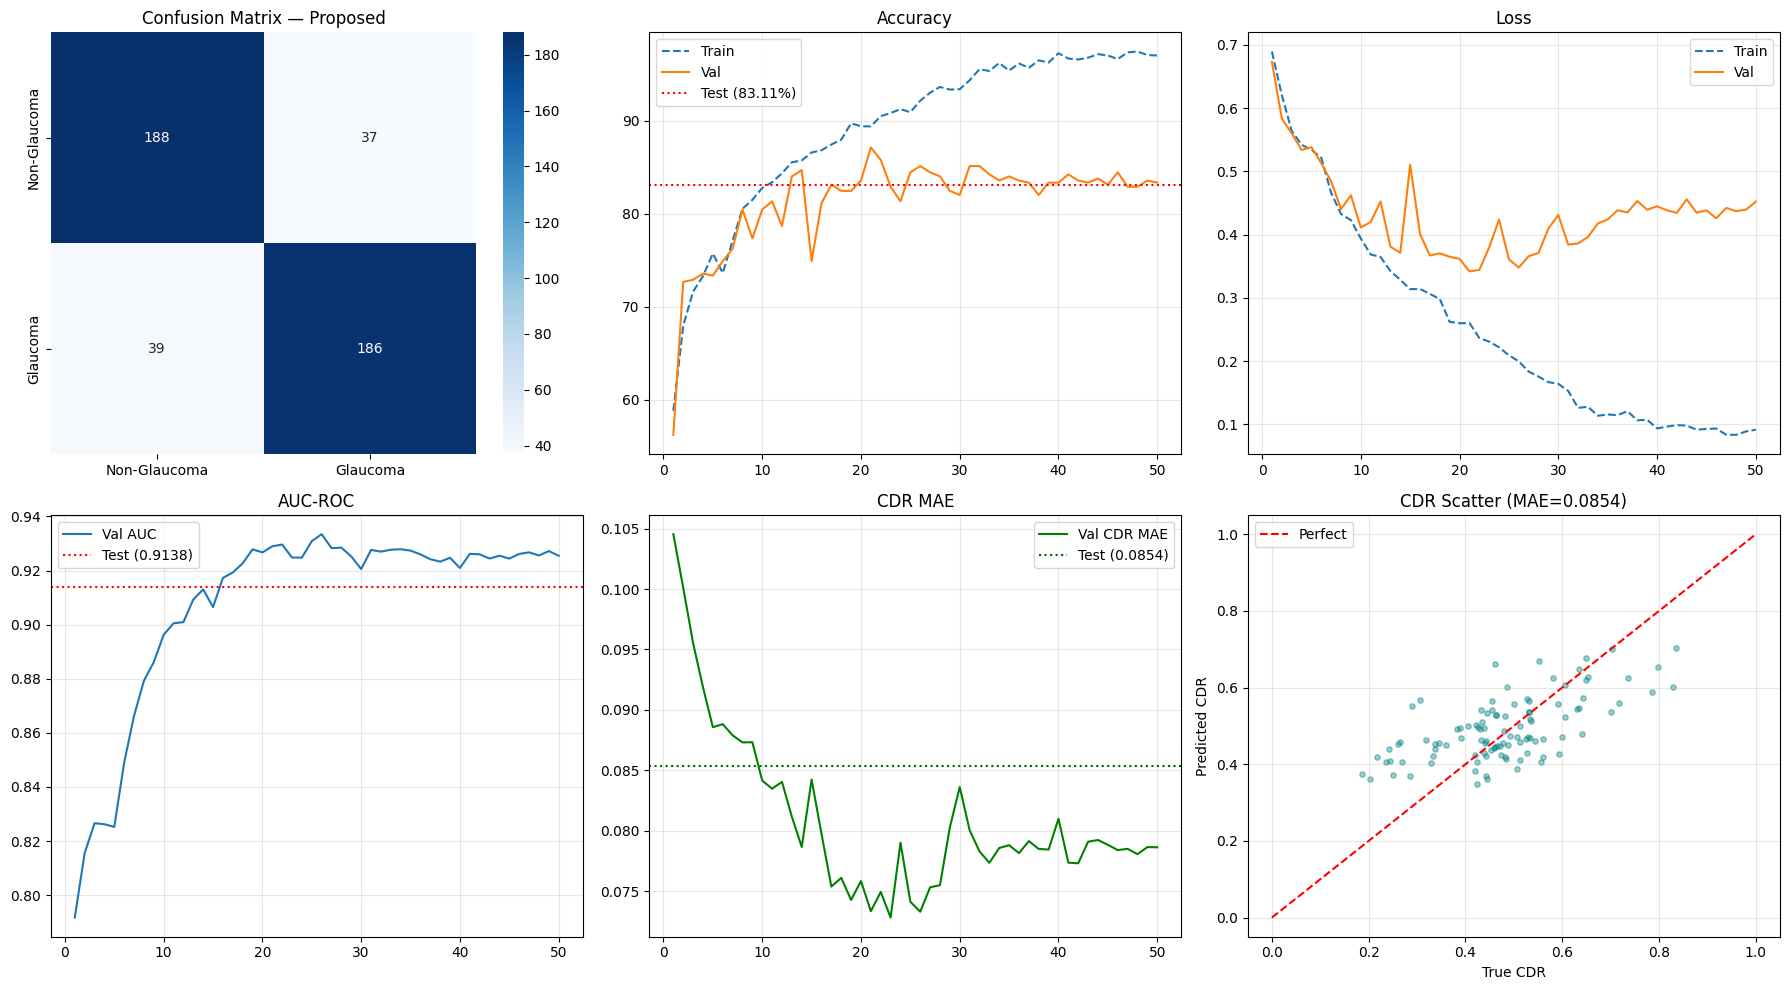

Results saved to: /content/drive/MyDrive/glaucoma-mtl/results/ablation_maxvit_cbam_only


In [ ]:
acc_ab, auc_ab, f1_ab, sens_ab, spec_ab, mae_ab, rmse_ab = evaluate_proposed(
    ablation_model, test_loader_mt, ABLATION_CKPT, ABLATION_RESULTS_DIR, history_ablation
)

## STEP 8: FINAL COMPARISON TABLE

In [ ]:
print("\n" + "="*85)
print("COMPLETE RESULTS — ALL MODELS (No Early Stopping, 50 Epochs)")
print("="*85)
print(f"{'Model':<38} {'Acc%':>7} {'AUC':>7} {'MacroF1':>8} {'Sens%':>7} {'Spec%':>7} {'CDR_MAE':>9}")
print("-"*85)

all_results = [
    ("DenseNet121 (Baseline)",           acc_d*100, auc_d, f1_d, sens_d*100, spec_d*100, "N/A"),
    ("MaxViT-Tiny + CBAM (Ablation)",    acc_ab*100, auc_ab, f1_ab, sens_ab*100, spec_ab*100, f"{mae_ab:.4f}"),
    ("MaxViT-Tiny + CBAM + GC (Proposed)", acc_p*100, auc_p, f1_p, sens_p*100, spec_p*100, f"{mae_p:.4f}"),
]
for (name, acc, auc, f1, sens, spec, cdr) in all_results:
    print(f"  {name:<36} {acc:>7.2f} {auc:>7.4f} {f1:>8.4f} {sens:>7.2f} {spec:>7.2f} {str(cdr):>9}")
print("="*85)
print("Note: Only results from models trained and evaluated in this notebook are displayed.")


COMPLETE RESULTS — ALL MODELS (No Early Stopping, 50 Epochs)
Model                                     Acc%     AUC  MacroF1   Sens%   Spec%   CDR_MAE
-------------------------------------------------------------------------------------
  DenseNet121 (Baseline)                 81.11  0.9237   0.8092   91.11   71.11       N/A
  MaxViT-Tiny + CBAM (Ablation)          83.11  0.9138   0.8311   82.67   83.56    0.0854
  MaxViT-Tiny + CBAM + GC (Proposed)     81.56  0.9185   0.8153   77.78   85.33    0.0760
Note: Only results from models trained and evaluated in this notebook are displayed.
